In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn pymupdf

   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
   --- ------------------------------------ 5.8/63.0 MB 32.7 MB/s eta 0:00:02
   -------- ------------------------------- 13.6/63.0 MB 34.7 MB/s eta 0:00:02
   -------------- ------------------------- 22.3/63.0 MB 36.9 MB/s eta 0:00:02
   ------------------ --------------------- 29.9/63.0 MB 36.8 MB/s eta 0:00:01
   ----------------------- ---------------- 37.5/63.0 MB 36.8 MB/s eta 0:00:01
   ------------------------------ --------- 48.2/63.0 MB 39.4 MB/s eta 0:00:01
   -------------------------------------- - 60.6/63.0 MB 41.9 MB/s eta 0:00:01
   ---------------------------------------  62.9/63.0 MB 42.2 MB/s eta 0:00:01
   ---------------------------------------- 63.0/63.0 MB 38.1 MB/s  0:00:01
   ---------------------------------------- 0.0/14.9 MB ? eta -:--:--
   ---------------------------------- ----- 12.8/14.9 MB 63.0 MB/s eta 0:00:01
   ---------------------------------------- 14.9/14.9 MB 49.8 MB/s  0:00:0

In [2]:
import fitz
from pathlib import Path

pdf_path = Path("The NIST Cybersecurity Framework (CSF) 2.0.pdf")

doc = fitz.open(pdf_path)

print("Total pages:", len(doc))

# Extract Appendix A pages containing the selected functions
text = ""

for page_num in range(20, 26):
    text += doc[page_num].get_text() + "\n"

print(text[:2000])

Total pages: 32
NIST CSWP 29 
 
The NIST Cybersecurity Framework (CSF) 2.0 
February 26, 2024 
 
 
 
16
GOVERN (GV): The organization’s cybersecurity risk management strategy, expectations, and 
policy are established, communicated, and monitored 
• Organizational Context (GV.OC): The circumstances — mission, stakeholder expectations, 
dependencies, and legal, regulatory, and contractual requirements — surrounding the 
organization’s cybersecurity risk management decisions are understood 
o GV.OC-01: The organizational mission is understood and informs cybersecurity risk 
management 
o GV.OC-02: Internal and external stakeholders are understood, and their needs and 
expectations regarding cybersecurity risk management are understood and considered 
o GV.OC-03: Legal, regulatory, and contractual requirements regarding cybersecurity — 
including privacy and civil liberties obligations — are understood and managed 
o GV.OC-04: Critical objectives, capabilities, and services that external 

C:\Users\wsher\anaconda3\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [6]:
import pymupdf
import pandas as pd
import re

doc = pymupdf.open(pdf_path)

# Extract Appendix A pages containing Govern, Identify, and Protect
text = "\n".join(
    doc[page_num].get_text()
    for page_num in range(20, 26)
)

# Stop before the Detect function
text = text.split("DETECT (DE):")[0]

pattern = r"\b((?:GV|ID|PR)\.[A-Z]{2}-\d{2}):\s*"

matches = list(re.finditer(pattern, text))

records = []

function_names = {
    "GV": "Govern",
    "ID": "Identify",
    "PR": "Protect"
}

for i, match in enumerate(matches):

    identifier = match.group(1)

    start = match.end()

    end = (
        matches[i + 1].start()
        if i + 1 < len(matches)
        else len(text)
    )

    statement = text[start:end]

    # Stop at the next bullet, category, or function
    statement = re.split(
        r"\n\s*(?:o|•)\s+|\n(?:GOVERN|IDENTIFY|PROTECT|DETECT)\s*\(",
        statement
    )[0]

    statement = re.sub(r"\s+", " ", statement).strip()

    # Remove trailing bullet markers
    statement = re.sub(r"\s+o$", "", statement)

    records.append({
        "nist_id": identifier,
        "requirement_text": statement,
        "function": function_names[identifier[:2]]
    })

df = pd.DataFrame(records)

print("Total statements:", len(df))
print("\nStatements per function:")
print(df["function"].value_counts())

display(df.head())

Total statements: 74

Statements per function:
function
Govern      31
Protect     22
Identify    21
Name: count, dtype: int64


,nist_id,requirement_text,function
0,GV.OC-01,The organizational mission is understood and i...,Govern
1,GV.OC-02,Internal and external stakeholders are underst...,Govern
2,GV.OC-03,"Legal, regulatory, and contractual requirement...",Govern
3,GV.OC-04,"Critical objectives, capabilities, and service...",Govern
4,GV.OC-05,"Outcomes, capabilities, and services that the ...",Govern


In [4]:
print("Statements per function:")
print(df["function"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate identifiers:")
print(df["nist_id"].duplicated().sum())

print("\nDuplicate statements:")
print(df["requirement_text"].duplicated().sum())

print("\nSample statements:")
for _, row in df.groupby("function").head(2).iterrows():
    print(f"\n{row['nist_id']} - {row['function']}")
    print(row["requirement_text"])

Statements per function:
function
Govern      31
Identify    21
Protect     19
Name: count, dtype: int64

Missing values:
nist_id             0
requirement_text    0
function            0
dtype: int64

Duplicate identifiers:
0

Duplicate statements:
0

Sample statements:

GV.OC-01 - Govern
The organizational mission is understood and informs cybersecurity risk management o

GV.OC-02 - Govern
Internal and external stakeholders are understood, and their needs and expectations regarding cybersecurity risk management are understood and considered o

ID.AM-01 - Identify
Inventories of hardware managed by the organization are maintained o

ID.AM-02 - Identify
Inventories of software, services, and systems managed by the organization are maintained o

PR.AA-01 - Protect
Identities and credentials for authorized users, services, and hardware are managed by the organization o

PR.AA-02 - Protect
Identities are proofed and bound to credentials based on the context of interactions o


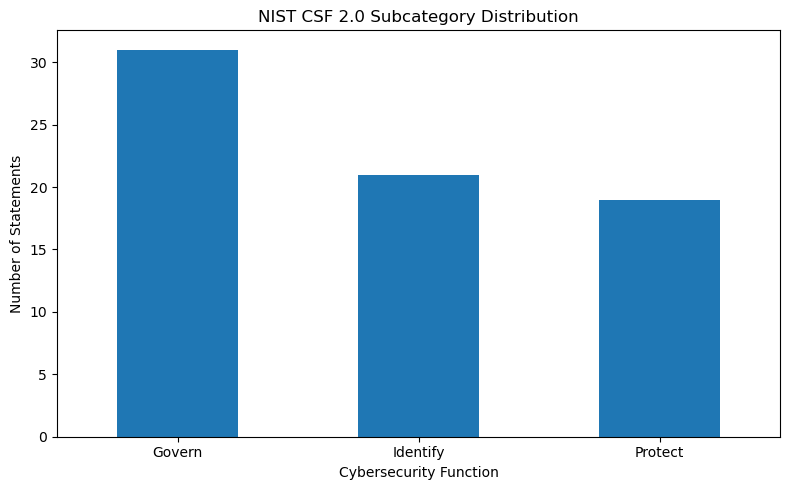

In [5]:
import matplotlib.pyplot as plt

counts = df["function"].value_counts()

plt.figure(figsize=(8, 5))
counts.plot(kind="bar")

plt.title("NIST CSF 2.0 Subcategory Distribution")
plt.xlabel("Cybersecurity Function")
plt.ylabel("Number of Statements")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [7]:
# Check the number of statements
assert len(df) == 74, "Expected 74 statements"

# Check for missing values
assert df.isnull().sum().sum() == 0

# Check for duplicate identifiers
assert df["nist_id"].duplicated().sum() == 0

# Check for duplicate statements
assert df["requirement_text"].duplicated().sum() == 0

# Check for leftover bullet markers
assert not df["requirement_text"].str.endswith(" o").any()

print("Dataset validation passed!")

print("\nClass distribution:")
print(df["function"].value_counts())

print("\nLast 5 statements:")
display(df.tail())

Dataset validation passed!

Class distribution:
function
Govern      31
Protect     22
Identify    21
Name: count, dtype: int64

Last 5 statements:


,nist_id,requirement_text,function
69,PR.PS-06,Secure software development practices are inte...,Protect
70,PR.IR-01,Networks and environments are protected from u...,Protect
71,PR.IR-02,The organization’s technology assets are prote...,Protect
72,PR.IR-03,Mechanisms are implemented to achieve resilien...,Protect
73,PR.IR-04,Adequate resource capacity to ensure availabil...,Protect


In [8]:
df.to_csv("nist_requirements.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
Step 10: Prepare the training and testing data

In [9]:
from sklearn.model_selection import train_test_split

# Text used for classification
X = df["requirement_text"]

# Correct NIST function labels
y = df["function"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training statements:", len(X_train))
print("Testing statements:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training statements: 55
Testing statements: 19

Training distribution:
function
Govern      23
Identify    16
Protect     16
Name: count, dtype: int64

Testing distribution:
function
Govern      8
Protect     6
Identify    5
Name: count, dtype: int64


In [ ]:
Step 11: Train the Logistic Regression model

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create the NLP classification pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict the NIST functions
y_pred = model.predict(X_test)

print("Model training completed!")
print("\nSample predictions:")

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(results.head(10))

Model training completed!

Sample predictions:


,Actual,Predicted
0,Identify,Govern
1,Govern,Govern
2,Govern,Govern
3,Govern,Govern
4,Identify,Identify
5,Identify,Identify
6,Govern,Govern
7,Identify,Govern
8,Govern,Govern
9,Identify,Identify


In [ ]:
Step 12: Evaluate your first model

Model Accuracy: 84.21%

Classification Report:
              precision    recall  f1-score   support

      Govern       0.73      1.00      0.84         8
    Identify       1.00      0.60      0.75         5
     Protect       1.00      0.83      0.91         6

    accuracy                           0.84        19
   macro avg       0.91      0.81      0.83        19
weighted avg       0.89      0.84      0.84        19



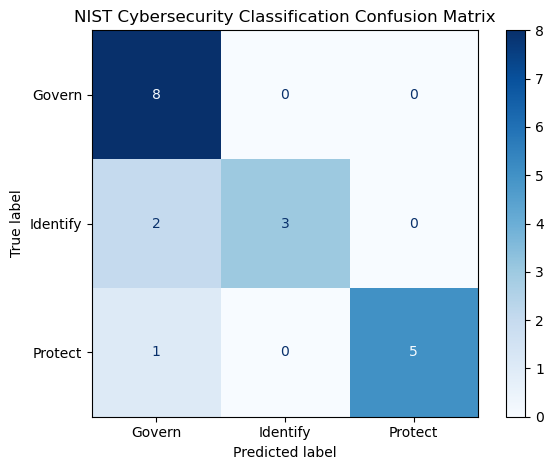

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Govern", "Identify", "Protect"],
    cmap="Blues"
)

plt.title("NIST Cybersecurity Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
Step 13: Analyze the incorrectly classified statements

In [12]:
# Create a dataframe containing the test statements
error_analysis = pd.DataFrame({
    "nist_id": df.loc[X_test.index, "nist_id"].values,
    "requirement_text": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

# Identify incorrect predictions
errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("Total misclassified statements:", len(errors))

display(errors)

Total misclassified statements: 3


,nist_id,requirement_text,actual,predicted
0,ID.RA-08,"Processes for receiving, analyzing, and respon...",Identify,Govern
7,ID.RA-05,"Threats, vulnerabilities, likelihoods, and imp...",Identify,Govern
11,PR.IR-03,Mechanisms are implemented to achieve resilien...,Protect,Govern


In [ ]:
Step 14: Compare against a simple baseline

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train.to_frame(), y_train)

dummy_pred = dummy.predict(X_test.to_frame())

print("Majority baseline accuracy:",
      round(accuracy_score(y_test, dummy_pred) * 100, 2), "%")

print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Majority baseline macro F1:",
      round(f1_score(y_test, dummy_pred, average="macro"), 3))

print("Logistic Regression macro F1:",
      round(f1_score(y_test, y_pred, average="macro"), 3))

Majority baseline accuracy: 42.11 %
Logistic Regression accuracy: 84.21 %
Majority baseline macro F1: 0.198
Logistic Regression macro F1: 0.834


In [ ]:
Step 15: Investigate why the model made these mistakes

In [14]:
# Display the complete text of misclassified statements
for _, row in errors.iterrows():
    print("=" * 75)
    print("NIST ID:", row["nist_id"])
    print("Actual function:", row["actual"])
    print("Predicted function:", row["predicted"])
    print("Statement:", row["requirement_text"])
    print()

NIST ID: ID.RA-08
Actual function: Identify
Predicted function: Govern
Statement: Processes for receiving, analyzing, and responding to vulnerability disclosures are established

NIST ID: ID.RA-05
Actual function: Identify
Predicted function: Govern
Statement: Threats, vulnerabilities, likelihoods, and impacts are used to understand inherent risk and inform risk response prioritization

NIST ID: PR.IR-03
Actual function: Protect
Predicted function: Govern
Statement: Mechanisms are implemented to achieve resilience requirements in normal and adverse situations



In [15]:
# Examine model probabilities for incorrect predictions
probabilities = model.predict_proba(X_test)
classes = model.named_steps["classifier"].classes_

prob_df = pd.DataFrame(
    probabilities,
    columns=classes,
    index=X_test.index
)

prob_df["nist_id"] = df.loc[X_test.index, "nist_id"]
prob_df["actual"] = y_test
prob_df["predicted"] = y_pred

incorrect_probabilities = prob_df[
    prob_df["actual"] != prob_df["predicted"]
]

display(incorrect_probabilities)

,Govern,Identify,Protect,nist_id,actual,predicted
45,0.403932,0.311135,0.284932,ID.RA-08,Identify,Govern
42,0.368755,0.361203,0.270041,ID.RA-05,Identify,Govern
72,0.396765,0.299082,0.304153,PR.IR-03,Protect,Govern


In [ ]:
Step 16: Run cross-validation

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    }
)

print("Cross-validation results:")

for i, (accuracy, f1) in enumerate(
    zip(
        scores["test_accuracy"],
        scores["test_macro_f1"]
    ),
    start=1
):
    print(
        f"Fold {i}: Accuracy = {accuracy:.3f}, "
        f"Macro F1 = {f1:.3f}"
    )

print("\nMean accuracy:",
      round(scores["test_accuracy"].mean(), 3))

print("Mean macro F1:",
      round(scores["test_macro_f1"].mean(), 3))

print("Accuracy standard deviation:",
      round(scores["test_accuracy"].std(), 3))

Cross-validation results:
Fold 1: Accuracy = 0.667, Macro F1 = 0.576
Fold 2: Accuracy = 0.867, Macro F1 = 0.868
Fold 3: Accuracy = 0.667, Macro F1 = 0.647
Fold 4: Accuracy = 0.800, Macro F1 = 0.792
Fold 5: Accuracy = 0.786, Macro F1 = 0.775

Mean accuracy: 0.757
Mean macro F1: 0.731
Accuracy standard deviation: 0.079


In [ ]:
Step 17: Compare two traditional NLP classifiers

In [17]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": model,
    "Multinomial Naive Bayes": nb_model
}

comparison = []

for name, classifier in models.items():

    scores = cross_validate(
        classifier,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        }
    )

    comparison.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Macro F1": scores["test_macro_f1"].mean()
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Model,Mean Accuracy,Mean Macro F1
0,Logistic Regression,0.757,0.731
1,Multinomial Naive Bayes,0.730,0.698


In [ ]:
DistillBERT

In [ ]:
Step 18: Install the required libraries

In [18]:
%pip install -U torch transformers datasets accelerate scikit-learn

  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   - -------------------------------------- 5.5/126.7 MB 31.6 MB/s eta 0:00:04
   ----- ---------------------------------- 18.9/126.7 MB 48.0 MB/s eta 0:00:03
   ---------- ----------------------------- 32.8/126.7 MB 53.5 MB/s eta 0:00:02
   --------------- ------------------------ 47.7/126.7 MB 58.2 MB/s eta 0:00:02
   ------------------- -------------------- 62.1/126.7 MB 60.8 MB/s eta 0:00:02
   ------------------------ --------------- 78.6/126.7 MB 64.1 MB/s eta 0:00:01
   ---------------------------- ----------- 91.2/126.7 MB 63.6 MB/s eta 0:00:01
   ------------------------------- ------- 103.0/126.7 MB 62.5 MB/s eta 0:00:01
   ----------------------------------- --- 114.3/126.7 MB 62.1 MB/s eta 0:00:01
   --------------------------------------  126.6/126.7 MB 62.5 MB/s eta 0:00:01
   --------------------------------------  126.6/126.7 MB 62.5 MB/s et

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.
streamlit 1.51.0 requires pyarrow<22,>=7.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
Step 19: Check your environment

In [19]:
import torch
import transformers
import pandas as pd

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Training device:", device)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

PyTorch version: 2.15.0+cpu
Transformers version: 5.22.2
GPU available: False
Training device: cpu
Training samples: 55
Testing samples: 19


In [ ]:
Step 20: Encode your NIST categories

In [20]:
label2id = {
    "Govern": 0,
    "Identify": 1,
    "Protect": 2
}

id2label = {
    0: "Govern",
    1: "Identify",
    2: "Protect"
}

train_df = pd.DataFrame({
    "text": X_train.tolist(),
    "labels": y_train.map(label2id).tolist()
})

test_df = pd.DataFrame({
    "text": X_test.tolist(),
    "labels": y_test.map(label2id).tolist()
})

print("Training dataset:")
display(train_df.head())

print("Testing dataset:")
display(test_df.head())

Training dataset:


,text,labels
0,Policy for managing cybersecurity risks is rev...,0
1,Assets are prioritized based on classification...,1
2,Improvements are identified from execution of ...,1
3,"Critical objectives, capabilities, and service...",0
4,Adequate resource capacity to ensure availabil...,2


Testing dataset:


,text,labels
0,"Processes for receiving, analyzing, and respon...",1
1,Organizational cybersecurity risk management p...,0
2,"A standardized method for calculating, documen...",0
3,Risk appetite and risk tolerance statements ar...,0
4,The authenticity and integrity of hardware and...,1


In [ ]:
Step 21: Tokenize your cybersecurity statements

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load your previously saved NIST dataset
df = pd.read_csv("nist_requirements.csv")

# Recreate the original training and testing split
X = df["requirement_text"]
y = df["function"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Convert NIST function labels to numbers
label2id = {
    "Govern": 0,
    "Identify": 1,
    "Protect": 2
}

id2label = {
    0: "Govern",
    1: "Identify",
    2: "Protect"
}

# Prepare datasets for DistilBERT
train_df = pd.DataFrame({
    "text": X_train.tolist(),
    "labels": y_train.map(label2id).tolist()
})

test_df = pd.DataFrame({
    "text": X_test.tolist(),
    "labels": y_test.map(label2id).tolist()
})

print("Dataset restored successfully!")
print("Total statements:", len(df))
print("Training statements:", len(train_df))
print("Testing statements:", len(test_df))

display(train_df.head())

Dataset restored successfully!
Total statements: 74
Training statements: 55
Testing statements: 19


,text,labels
0,Policy for managing cybersecurity risks is rev...,0
1,Assets are prioritized based on classification...,1
2,Improvements are identified from execution of ...,1
3,"Critical objectives, capabilities, and service...",0
4,Adequate resource capacity to ensure availabil...,2


In [5]:
from datasets import Dataset
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

print("Tokenization completed!")
print("Training records:", len(train_dataset))
print("Testing records:", len(test_dataset))

Map:   0%|          | 0/55 [00:00<?, ? examples/s]

Map:   0%|          | 0/19 [00:00<?, ? examples/s]

Tokenization completed!
Training records: 55
Testing records: 19


In [ ]:
Step 22: Load DistilBERT

In [6]:
from transformers import AutoModelForSequenceClassification

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("DistilBERT loaded successfully!")

C:\Users\wsher\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\wsher\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!


In [ ]:
Step 23: Configure training

In [7]:
from transformers import TrainingArguments, Trainer
from transformers import DataCollatorWithPadding

training_args = TrainingArguments(
    output_dir="./distilbert_nist_results",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=42,
    data_seed=42,
    fp16=False
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=train_dataset,
    processing_class=tokenizer,
    data_collator=data_collator
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [ ]:
Step 24: Train DistilBERT

In [8]:
print("Starting DistilBERT training...")

training_result = trainer.train()

print("DistilBERT training completed!")
print(training_result.metrics)

Starting DistilBERT training...


C:\Users\wsher\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
14,1.057675
28,0.926759
42,0.827784


DistilBERT training completed!
{'train_runtime': 32.4282, 'train_samples_per_second': 5.088, 'train_steps_per_second': 1.295, 'total_flos': 1441643571144.0, 'train_loss': 0.9374062901451474, 'epoch': 3.0}


In [ ]:
Step 25: Evaluate DistilBERT

C:\Users\wsher\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DistilBERT Accuracy: 63.16%
DistilBERT Macro F1: 0.604

Classification Report:
              precision    recall  f1-score   support

      Govern       0.58      0.88      0.70         8
    Identify       0.50      0.40      0.44         5
     Protect       1.00      0.50      0.67         6

    accuracy                           0.63        19
   macro avg       0.69      0.59      0.60        19
weighted avg       0.69      0.63      0.62        19



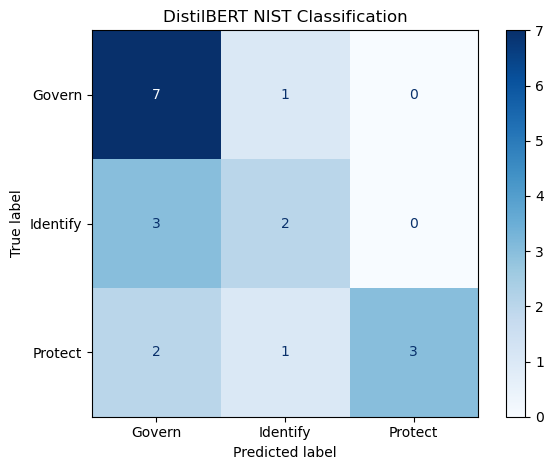

In [9]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

predictions = trainer.predict(test_dataset)

predicted_ids = np.argmax(
    predictions.predictions,
    axis=1
)

actual_ids = test_df["labels"].to_numpy()

distilbert_accuracy = accuracy_score(
    actual_ids,
    predicted_ids
)

distilbert_macro_f1 = f1_score(
    actual_ids,
    predicted_ids,
    average="macro"
)

print(f"DistilBERT Accuracy: {distilbert_accuracy:.2%}")
print(f"DistilBERT Macro F1: {distilbert_macro_f1:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        actual_ids,
        predicted_ids,
        labels=[0, 1, 2],
        target_names=["Govern", "Identify", "Protect"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    actual_ids,
    predicted_ids,
    display_labels=["Govern", "Identify", "Protect"],
    cmap="Blues"
)

plt.title("DistilBERT NIST Classification")
plt.tight_layout()
plt.show()

In [ ]:
Step 26: Compare DistilBERT with Logistic Regression

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Recreate majority-class baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train.to_frame(), y_train)
dummy_pred = dummy.predict(X_test.to_frame())

# Recreate Logistic Regression model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Traditional model predictions restored!")
print("Majority baseline accuracy:",
      round(accuracy_score(y_test, dummy_pred) * 100, 2), "%")
print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Traditional model predictions restored!
Majority baseline accuracy: 42.11 %
Logistic Regression accuracy: 84.21 %


In [12]:
comparison_test = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Logistic Regression",
        "DistilBERT"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, y_pred),
        distilbert_accuracy
    ],
    "Test Macro F1": [
        f1_score(y_test, dummy_pred, average="macro"),
        f1_score(y_test, y_pred, average="macro"),
        distilbert_macro_f1
    ]
})

display(comparison_test.round(3))

,Model,Test Accuracy,Test Macro F1
0,Majority Baseline,0.421,0.198
1,Logistic Regression,0.842,0.834
2,DistilBERT,0.632,0.604


In [ ]:
Step 27: Save your trained model and results

In [13]:
# Save trained DistilBERT model
trainer.save_model("./nist_distilbert_model")

# Save tokenizer
tokenizer.save_pretrained("./nist_distilbert_model")

# Save model comparison results
comparison_test.to_csv(
    "nist_distilbert_comparison.csv",
    index=False
)

print("DistilBERT model saved successfully!")
print("Comparison results saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved successfully!
Comparison results saved successfully!


In [14]:
trainer.save_model("./nist_distilbert_model")
tokenizer.save_pretrained("./nist_distilbert_model")

comparison_test.to_csv(
    "nist_distilbert_comparison.csv",
    index=False
)

print("Model and comparison saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and comparison saved successfully!


In [22]:
%pip uninstall -y pyarrow

Found existing installation: pyarrow 26.0.1
Uninstalling pyarrow-26.0.1:
  Successfully uninstalled pyarrow-26.0.1
Note: you may need to restart the kernel to use updated packages.


In [23]:
%pip install --no-cache-dir --force-reinstall --no-deps pyarrow

   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   --------- ------------------------------ 6.6/29.0 MB 40.5 MB/s eta 0:00:01
   ------------------ --------------------- 13.6/29.0 MB 38.0 MB/s eta 0:00:01
   ----------------------------- ---------- 21.5/29.0 MB 37.4 MB/s eta 0:00:01
   ---------------------------------------- 29.0/29.0 MB 38.6 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pyarrow
import pyarrow.dataset
from datasets import Dataset

print("PyArrow version:", pyarrow.__version__)
print("PyArrow dataset import: SUCCESS")
print("Hugging Face datasets import: SUCCESS")

PyArrow version: 26.0.1
PyArrow dataset import: SUCCESS
Hugging Face datasets import: SUCCESS


In [15]:
from pathlib import Path

# Create results folder
Path("results").mkdir(exist_ok=True)

# Save comparison results
comparison_test.to_csv(
    "results/model_comparison.csv",
    index=False
)

# Save trained DistilBERT model
trainer.save_model("nist_distilbert_model")
tokenizer.save_pretrained("nist_distilbert_model")

print("Research files organized successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Research files organized successfully!


In [ ]:
Requirements txt

In [16]:
from pathlib import Path

requirements = """pandas
numpy
scikit-learn
matplotlib
PyMuPDF
torch
transformers
datasets
accelerate
pyarrow
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [ ]:
Create Readme.md

In [17]:
readme = """# NIST Cybersecurity Framework NLP Classification

## Project Overview

This research project uses Natural Language Processing (NLP)
to classify cybersecurity statements from the NIST
Cybersecurity Framework (CSF) 2.0.

The project focuses on three cybersecurity functions:
- Govern
- Identify
- Protect

## Dataset

74 NIST CSF 2.0 statements:
- Govern: 31
- Identify: 21
- Protect: 22

Training dataset: 55 statements
Testing dataset: 19 statements

## Machine Learning Models

1. TF-IDF + Logistic Regression
2. TF-IDF + Multinomial Naive Bayes
3. DistilBERT

## Preliminary Results

Held-out test results:

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Majority Baseline | 42.11% | 0.198 |
| Logistic Regression | 84.21% | 0.834 |
| DistilBERT | 63.16% | 0.604 |

Five-fold cross-validation results:

| Model | Mean Accuracy | Mean Macro F1 |
|---|---:|---:|
| Logistic Regression | 75.7% | 0.731 |
| Multinomial Naive Bayes | 73.0% | 0.698 |

## Key Findings

Logistic Regression outperformed DistilBERT on the
19-statement held-out test set.

The small dataset may have limited DistilBERT's
fine-tuning performance.

Further evaluation is needed before generalizing
these findings.

## Technologies

Python, Jupyter Notebook, pandas, scikit-learn,
PyTorch, Hugging Face Transformers, and PyMuPDF.

## Data Source

NIST Cybersecurity Framework (CSF) 2.0

https://doi.org/10.6028/NIST.CSWP.29
"""

Path("README.md").write_text(
    readme,
    encoding="utf-8"
)

print("README.md created successfully!")

README.md created successfully!
